In [1]:
from collections import Counter
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import sklearn
from sklearn.ensemble import RandomForestClassifier
import shap
# Load data
data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\296×87.xlsx")
X = data.iloc[:, 3:]
X
feature_names = X.columns
X = StandardScaler().fit_transform(X)
# Normalize data.
min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(296, 87)

In [2]:
# Get reported structure IDs
def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage4\benchmark4.xlsx"
reported_structures = extract_numbers(file_path)
print(reported_structures)

# Train a KNN model to reassign noise points generated by DBSCAN.
def remove_noise_by_nearest_cluster(X, labels):
    """Assign noise points to the cluster of the nearest non-noise points"""
    # Find all noise points
    noise_mask = labels == -1

    # Return directly if there are no noise points
    if not any(noise_mask):
        return labels

    # Find non-noise points
    core_samples = ~noise_mask
    X_core = X[core_samples]
    y_core = labels[core_samples]

    # Check whether non-noise points exist
    if len(X_core) == 0:
        # If all points are noise, assign them to a cluster randomly
        new_labels = np.zeros_like(labels)
        return new_labels

    # Train the KNN classifier
    nn = NearestNeighbors(n_neighbors=1).fit(X_core)
    distances, indices = nn.kneighbors(X[noise_mask])

    # Assign noise points to the nearest non-noise cluster
    new_labels = labels.copy()
    new_labels[noise_mask] = y_core[indices.flatten()]
    return new_labels

[14, 15, 16, 17, 95, 111, 142, 144, 153, 157, 171, 180, 199, 261, 283]


In [3]:
pca = PCA(n_components= 0.85)
pca_data = pca.fit_transform(X)
ratios = pca.explained_variance_ratio_   # Variance ratio explained by each principal component.
components = pca.components_    # Loadings of the principal components on the original features.
X = pd.DataFrame(X)
# Convert the loading matrix to a DataFrame for Excel export and subsequent analysis.
components_df = pd.DataFrame(
    components,
    columns=X.columns,  # Use the original feature names as column names
    index=[f"PC{i+1}" for i in range(components.shape[0])]  # Use PC1, PC2, etc. as row names
)
# Export to an Excel file
output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)
db = DBSCAN(eps=0.21,metric='cosine', min_samples=9)
db.fit(pca_data)
labels = db.labels_
labels = remove_noise_by_nearest_cluster(pca_data, labels)

df = pd.DataFrame(labels)
df.to_excel("DBSCAN_result_1.xlsx", index=False)

print(f"\nSilhouette score: {silhouette_score(pca_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(pca_data, labels):.2f}")

            # Add labels to the original data
data['cluster_label'] = labels
unique_labels = np.unique(labels)

dict = {}    # Summarize each cluster.
                    # Summarize each cluster
label_1 = []
for num  in  reported_structures:
    label = labels[num-1]
    label_1.append(int(label))
print(label_1)

for label in unique_labels:
                # All samples in the current cluster
    cluster_samples = data[data['cluster_label'] == label]
    total_in_cluster = len(cluster_samples)

                # Number of reported samples
    reported_in_cluster = len([num for num in cluster_samples['number']
                                        if num in reported_structures])

    print(f"Cluster {label}: {reported_in_cluster}/{total_in_cluster} "
                    f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")

            # Print label distribution
print("Label distribution:", Counter(labels))


Silhouette score: 0.14 
Calinski-Harabasz score: 41.86
[2, 1, 1, 0, 2, 0, 0, 0, 0, 1, 2, 0, 1, 1, 2]
Cluster 0: 6/127 (Reported ratio: 4.72%)
Cluster 1: 5/63 (Reported ratio: 7.94%)
Cluster 2: 4/42 (Reported ratio: 9.52%)
Cluster 3: 0/39 (Reported ratio: 0.00%)
Cluster 4: 0/25 (Reported ratio: 0.00%)
Label distribution: Counter({np.int64(0): 127, np.int64(1): 63, np.int64(2): 42, np.int64(3): 39, np.int64(4): 25})


In [4]:
# 3. Build the surrogate classification model
# Goal: train a classifier to reproduce the clustering-derived labels
clf = RandomForestClassifier(n_estimators=100, random_state=42)   # Create 100 decision trees.
clf.fit(pca_data, labels)
# Check how closely the classifier reproduces the clustering result.
print(f"Training fidelity accuracy: {clf.score(pca_data, labels):.2f}")

# ============================================================
# RF surrogate classifier fidelity evaluation
# Evaluate RF fidelity to the original clustering labels rather than physical-property prediction.
# Use the same evaluation protocol as for the KMeans surrogate.
# ============================================================
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Inspect cluster sizes and determine a feasible stratified cross-validation fold count.
class_counts = Counter(labels)
min_class_count = min(class_counts.values())
n_splits = min(5, min_class_count)

if n_splits < 2:
    raise ValueError(
        f"The smallest class contains only {min_class_count} samples, so at least 2-fold stratified cross-validation is not possible."
    )

print("\n========== RF surrogate classifier fidelity evaluation ==========")
print("Samples per cluster:", {k: v for k, v in sorted(class_counts.items())})
print(f"Use stratified {n_splits}-fold cross-validation")

# Use the same RF parameters as in the final SHAP analysis;
# a new RF is trained in each cross-validation fold.
rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Macro-F1": "f1_macro",
    "Balanced Accuracy": "balanced_accuracy"
}

cv_results = cross_validate(
    rf_cv,
    pca_data,
    labels,
    cv=StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    ),
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("\nCross-validation results (mean ± std):")
for metric_name in scoring:
    scores = cv_results[f"test_{metric_name}"]
    print(f"{metric_name}: {scores.mean():.4f} ± {scores.std(ddof=1):.4f}")

# Generate out-of-fold (OOF) predictions:
# each sample is predicted by a model that did not use that sample for training.
cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

oof_pred = cross_val_predict(
    rf_cv,
    pca_data,
    labels,
    cv=cv,
    n_jobs=-1
)

oof_acc = accuracy_score(labels, oof_pred)
oof_macro_f1 = f1_score(labels, oof_pred, average="macro")
oof_bal_acc = balanced_accuracy_score(labels, oof_pred)

print("\nOverall OOF evaluation:")
print(f"OOF Accuracy:          {oof_acc:.4f}")
print(f"OOF Macro-F1:          {oof_macro_f1:.4f}")
print(f"OOF Balanced Accuracy: {oof_bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(
    labels,
    oof_pred,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(labels, oof_pred))

# Note:
# These metrics quantify the fidelity of the RF surrogate classifier to the original clustering partition.
# The classifier used for SHAP is still the RF refitted on the full dataset above.


Training fidelity accuracy: 1.00

========== RF surrogate classifier fidelity evaluation ==========
Samples per cluster: {np.int64(0): 127, np.int64(1): 63, np.int64(2): 42, np.int64(3): 39, np.int64(4): 25}
Use stratified 5-fold cross-validation

Cross-validation results (mean ± std):
Accuracy: 0.8718 ± 0.0274
Macro-F1: 0.7988 ± 0.0646
Balanced Accuracy: 0.7975 ± 0.0612

Overall OOF evaluation:
OOF Accuracy:          0.8716
OOF Macro-F1:          0.8059
OOF Balanced Accuracy: 0.7977

Classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       127
           1     0.8116    0.8889    0.8485        63
           2     0.6905    0.6905    0.6905        42
           3     0.7895    0.7692    0.7792        39
           4     0.8000    0.6400    0.7111        25

    accuracy                         0.8716       296
   macro avg     0.8183    0.7977    0.8059       296
weighted avg     0.8714    0.8716    0.8703       296

In [5]:
# 4. Use SHAP to interpret the surrogate classification
# Use TreeExplainer because it is efficient for random forests.
explainer = shap.TreeExplainer(clf)   # Create an explainer object.
shap_values = explainer.shap_values(pca_data)   # Calculate SHAP values for each sample.
print(shap_values.shape)   # Print the SHAP-value shape.

(296, 19, 5)


Generating the global SHAP summary for Cluster 2 and saving it as PDF...


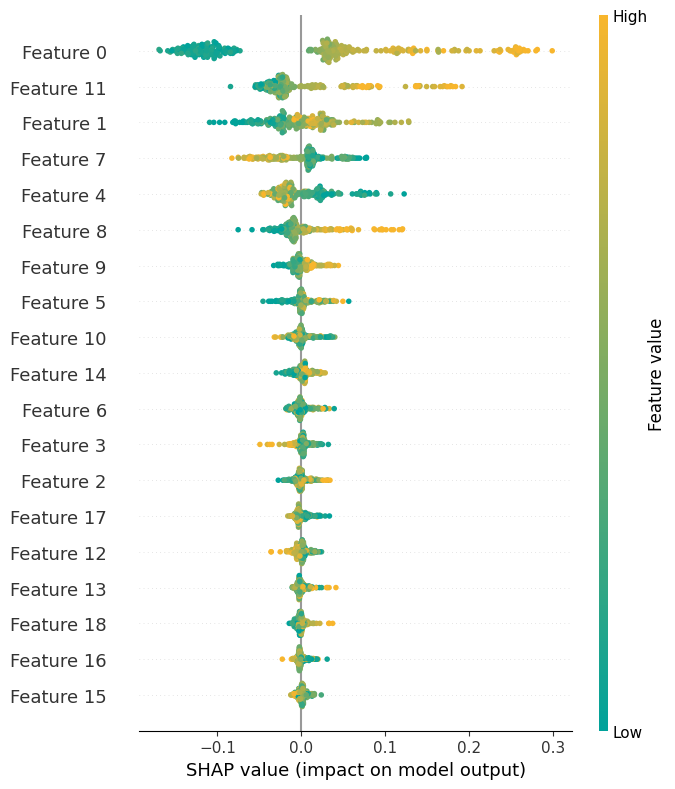

Saved: Cluster2_Summary_Plot.pdf


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import matplotlib.colors as mcolors # Import the matplotlib color module

# 1. Convert the nested list to a NumPy array
shap_array = np.array(shap_values)

# 2. Extract the data for Cluster 0
# Assume shape (samples, features, classes) and extract class 0
# Index [:, :, 0] extracts Cluster 0.
cluster_4_values = shap_array[:, :pca_data.shape[1], 2]

# 3. Set fixed width and height
fixed_width = 7  # Modify this value if needed (inches)
fixed_height = 8  # Adjust height according to feature count

# ---------- Custom colormap ----------
# Replace the default SHAP low/high colors with the specified custom colors.
custom_colors = ["#00A29A", "#F8B62D"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_shap_cmap", custom_colors)
# --------------------------------------------------------


# 3. Plot and save
print("Generating the global SHAP summary for Cluster 2 and saving it as PDF...")

# Create the figure with a white background
plt.figure(facecolor='white')


# Pass cmap=custom_cmap and keep show=False
shap.summary_plot(
    cluster_4_values,
    pca_data,
    plot_size=(fixed_width, fixed_height), # Controls plot width
    cmap=custom_cmap,                      # Apply the custom colormap
    show=False
)

# Get the current figure and set the background
fig = plt.gcf()
fig.set_facecolor('white')

# 4. Save as PDF
# bbox_inches='tight' Ensure feature names are not clipped
plt.savefig("Cluster0_Summary_Plot.pdf", bbox_inches='tight', facecolor='white')

# Call show at the end only if an editor preview is needed
plt.show()

print("Saved: Cluster2_Summary_Plot.pdf")